In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
df = pd.read_csv('RealEstate_Prices.csv')

print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
   ID             Date     Price  Bedrooms  Bathrooms  Sqft_living  Sqft_lot  \
0   1  20140916T000000  280000.0         6       3.00         2400      9373   
1   2  20150422T000000  300000.0         6       3.00         2400      9373   
2   3  20140508T000000  647500.0         4       1.75         2060     26036   
3   4  20140811T000000  400000.0         3       1.00         1460     43000   
4   5  20150401T000000  235000.0         3       1.00         1430      7599   

   Floors  Waterfront  View  ...  Grade  Sqft_above  Sqft_basement  Yr_built  \
0     2.0           0     0  ...      7        2400              0      1991   
1     2.0           0     0  ...      7        2400              0      1991   
2     1.0           0     0  ...      8        1160            900      1947   
3     1.0           0     0  ...      7        1460              0      1952   
4     1.5           0     0  ...      6        1010            420      1930   

   Yr_ren

In [6]:
# Display first five rows
print(df.head())

# Display dataset information
print(df.info())

# Display rows and columns
print("Shape:", df.shape)

# Display statistical summary
print(df.describe())

   ID             Date     Price  Bedrooms  Bathrooms  Sqft_living  Sqft_lot  \
0   1  20140916T000000  280000.0         6       3.00         2400      9373   
1   2  20150422T000000  300000.0         6       3.00         2400      9373   
2   3  20140508T000000  647500.0         4       1.75         2060     26036   
3   4  20140811T000000  400000.0         3       1.00         1460     43000   
4   5  20150401T000000  235000.0         3       1.00         1430      7599   

   Floors  Waterfront  View  ...  Grade  Sqft_above  Sqft_basement  Yr_built  \
0     2.0           0     0  ...      7        2400              0      1991   
1     2.0           0     0  ...      7        2400              0      1991   
2     1.0           0     0  ...      8        1160            900      1947   
3     1.0           0     0  ...      7        1460              0      1952   
4     1.5           0     0  ...      6        1010            420      1930   

   Yr_renovated  zipcode      Lat     

In [27]:
df.columns = df.columns.str.strip()

df.columns = df.columns.str.replace(' ', '_')

print("Clean Column Names:")
print(df.columns.tolist())

Clean Column Names:
['ID', 'Date', 'Price', 'Bedrooms', 'Bathrooms', 'Sqft_living', 'Sqft_lot', 'Floors', 'Waterfront', 'View', 'Condition', 'Grade', 'Sqft_above', 'Sqft_basement', 'Yr_built', 'Yr_renovated', 'zipcode', 'Lat', 'Long', 'Sqft_living15', 'Sqft_lot15']


In [28]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Fill numerical missing values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
ID               0
Date             0
Price            0
Bedrooms         0
Bathrooms        0
Sqft_living      0
Sqft_lot         0
Floors           0
Waterfront       0
View             0
Condition        0
Grade            0
Sqft_above       0
Sqft_basement    0
Yr_built         0
Yr_renovated     0
zipcode          0
Lat              0
Long             0
Sqft_living15    0
Sqft_lot15       0
dtype: int64

Missing Values After Cleaning:
ID               0
Date             0
Price            0
Bedrooms         0
Bathrooms        0
Sqft_living      0
Sqft_lot         0
Floors           0
Waterfront       0
View             0
Condition        0
Grade            0
Sqft_above       0
Sqft_basement    0
Yr_built         0
Yr_renovated     0
zipcode          0
Lat              0
Long             0
Sqft_living15    0
Sqft_lot15       0
dtype: int64


In [29]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates Removed Successfully!")

print("Updated Shape:", df.shape)

Duplicate Records: 0
Duplicates Removed Successfully!
Updated Shape: (21613, 21)


In [30]:
# Convert Date column into datetime
df['Date'] = pd.to_datetime(
    df['Date'],
    format='%Y%m%dT%H%M%S',
    errors='coerce'
)

# Extract year and month
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

# Create price per square foot
df['Price_Per_Sqft'] = df['Price'] / df['Sqft_living']

print(df.head())

   ID       Date     Price  Bedrooms  Bathrooms  Sqft_living  Sqft_lot  \
0   1 2014-09-16  280000.0         6       3.00         2400      9373   
1   2 2015-04-22  300000.0         6       3.00         2400      9373   
2   3 2014-05-08  647500.0         4       1.75         2060     26036   
3   4 2014-08-11  400000.0         3       1.00         1460     43000   
4   5 2015-04-01  235000.0         3       1.00         1430      7599   

   Floors  Waterfront  View  ...  Yr_built  Yr_renovated  zipcode      Lat  \
0     2.0           0     0  ...      1991             0    98002  47.3262   
1     2.0           0     0  ...      1991             0    98002  47.3262   
2     1.0           0     0  ...      1947             0    98166  47.4444   
3     1.0           0     0  ...      1952             0    98166  47.4434   
4     1.5           0     0  ...      1930             0    98168  47.4783   

      Long  Sqft_living15  Sqft_lot15  Year  Month  Price_Per_Sqft  
0 -122.214       

In [38]:
# Filter properties with price greater than 500000
filtered_data = df[df['Price'] > 500000]

print("Filtered Properties:")
print(filtered_data.head())

# Select available important columns
columns = [
    'Price',
    'Bedrooms',
    'Bathrooms',
    'Sqft_living',
    'Zipcode'
]

available_columns = [
    col for col in columns if col in df.columns
]

selected_data = df[available_columns]

print("\nSelected Data:")
print(selected_data.head())

Filtered Properties:
    ID       Date     Price  Bedrooms  Bathrooms  Sqft_living  Sqft_lot  \
2    3 2014-05-08  647500.0         4       1.75         2060     26036   
6    7 2015-03-30  680000.0         4       2.75         2220      5310   
14  15 2014-08-05  520000.0         3       2.00         1410      2700   
16  17 2014-12-18  630000.0         5       1.00         3020      4800   
19  20 2014-07-21  570000.0         3       2.50         1530      3296   

    Floors  Waterfront  View  ...  Yr_built  Yr_renovated  zipcode      Lat  \
2      1.0           0     0  ...      1947             0    98166  47.4444   
6      1.0           0     0  ...      1951             0    98144  47.5801   
14     2.0           0     0  ...      1902             0    98122  47.6029   
16     2.0           0     0  ...      1901             0    98122  47.6025   
19     2.0           0     0  ...      1998             0    98007  47.6181   

       Long  Sqft_living15  Sqft_lot15  Year  Month  

In [39]:
# Convert zipcode into categorical format
df['zipcode'] = df['zipcode'].astype(str)

# Apply one-hot encoding
encoded_data = pd.get_dummies(
    df,
    columns=['zipcode'],
    drop_first=True
)

print("Categorical Variables Encoded Successfully!")

print(encoded_data.head())

Categorical Variables Encoded Successfully!
   ID       Date     Price  Bedrooms  Bathrooms  Sqft_living  Sqft_lot  \
0   1 2014-09-16  280000.0         6       3.00         2400      9373   
1   2 2015-04-22  300000.0         6       3.00         2400      9373   
2   3 2014-05-08  647500.0         4       1.75         2060     26036   
3   4 2014-08-11  400000.0         3       1.00         1460     43000   
4   5 2015-04-01  235000.0         3       1.00         1430      7599   

   Floors  Waterfront  View  ...  zipcode_98146  zipcode_98148  zipcode_98155  \
0     2.0           0     0  ...          False          False          False   
1     2.0           0     0  ...          False          False          False   
2     1.0           0     0  ...          False          False          False   
3     1.0           0     0  ...          False          False          False   
4     1.5           0     0  ...          False          False          False   

   zipcode_98166  zipcod

In [41]:
# Average price by bedrooms
bedroom_analysis = df.groupby('Bedrooms')['Price'].mean()

print("Average House Price by Bedrooms:")
print(bedroom_analysis)

# Average price by zipcode
location_analysis = df.groupby('zipcode')['Price'].mean()

print("\nAverage House Price by Location:")
print(location_analysis.head(10))

Average House Price by Bedrooms:
Bedrooms
0     4.102231e+05
1     3.176580e+05
2     4.013877e+05
3     4.662766e+05
4     6.355647e+05
5     7.868741e+05
6     8.258535e+05
7     9.514478e+05
8     1.105077e+06
9     8.939998e+05
10    8.200000e+05
11    5.200000e+05
33    6.400000e+05
Name: Price, dtype: float64

Average House Price by Location:
zipcode
98001    2.808047e+05
98002    2.342840e+05
98003    2.941113e+05
98004    1.356524e+06
98005    8.102897e+05
98006    8.599386e+05
98007    6.172540e+05
98008    6.456282e+05
98010    4.236660e+05
98011    4.903771e+05
Name: Price, dtype: float64


In [43]:
# Calculate Q1 and Q3
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Handle outliers
df['Price'] = df['Price'].clip(lower, upper)

print("Outliers Handled Successfully!")

Outliers Handled Successfully!


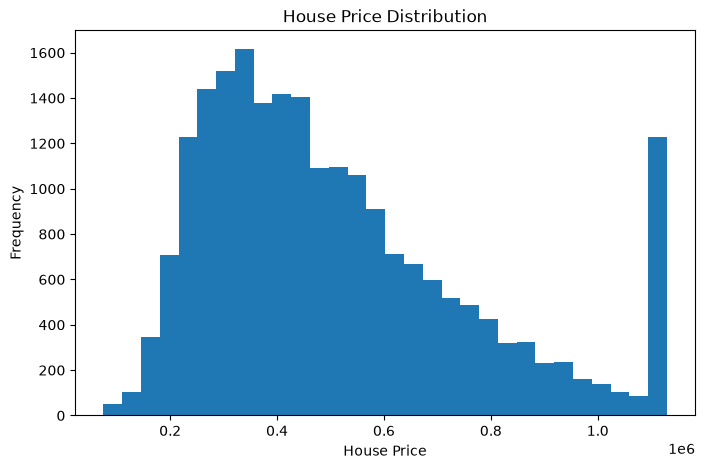

In [45]:
plt.figure(figsize=(8, 5))

plt.hist(df['Price'], bins=30)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

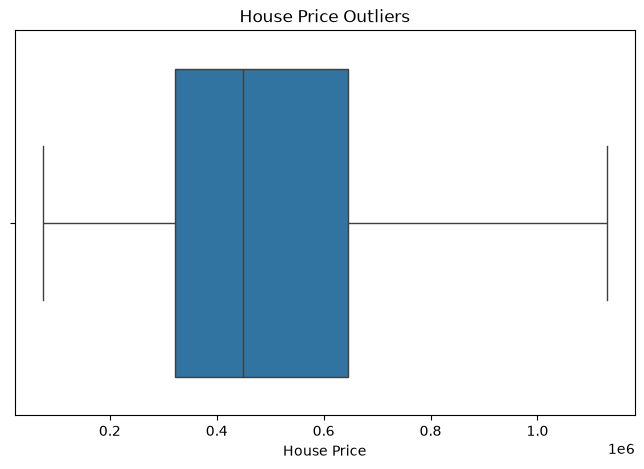

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Price'])

plt.title("House Price Outliers")
plt.xlabel("House Price")

plt.show()

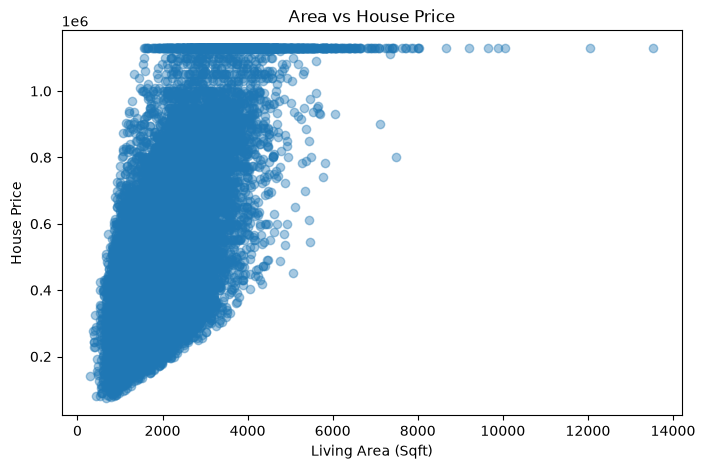

In [47]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Sqft_living'],
    df['Price'],
    alpha=0.4
)

plt.title("Area vs House Price")
plt.xlabel("Living Area (Sqft)")
plt.ylabel("House Price")

plt.show()

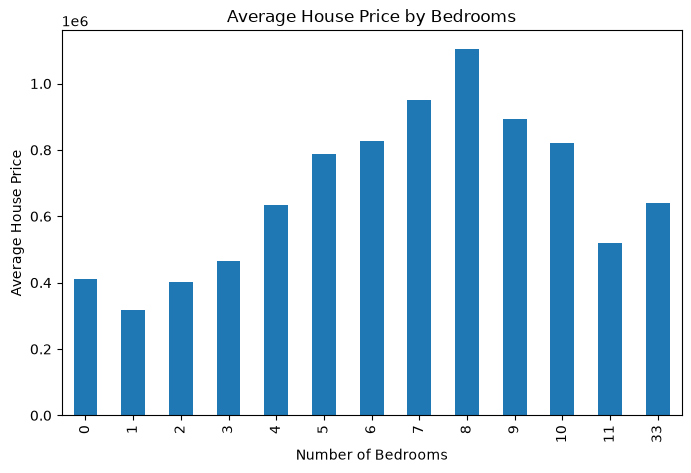

In [48]:
plt.figure(figsize=(8, 5))

bedroom_analysis.plot(kind='bar')

plt.title("Average House Price by Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average House Price")

plt.show()

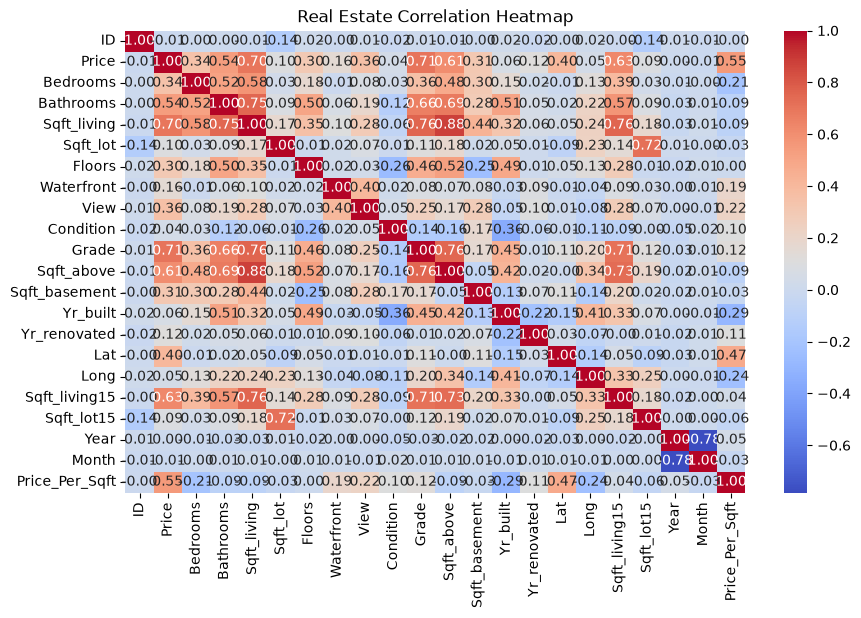

In [49]:
plt.figure(figsize=(10, 6))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Real Estate Correlation Heatmap")

plt.show()

In [50]:
df.to_csv('RealEstate_Prices_Cleaned.csv', index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!
